# Malicious_TLS 특징 추출 설계
**캡스톤디자인 I** - 특징 추출 최적화 기반 암호화된 공격 트래픽 탐지 및 분류 시스템
팀장: 김강민 | 팀원: 서은빈

---
### 폴더 구조
```
capstone2026/output/
├── cleansing/
│   └── malicious_tls_cleaned.csv     ← 입력
└── features/
    └── Malicious_TLS/                ← 출력
        ├── malicious_tls_corr_heatmap.png
        ├── malicious_tls_feature_importance.png
        ├── malicious_tls_features_final.csv
        └── malicious_tls_selected_features.txt
```

## 0. Google Drive 마운트

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE_DIR   = '/content/drive/MyDrive/capstone2026'
DATA_PATH  = os.path.join(BASE_DIR, 'output', 'cleansing', 'malicious_tls_cleaned.csv')
OUTPUT_DIR = os.path.join(BASE_DIR, 'output', 'features', 'Malicious_TLS')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f'DATA_PATH : {DATA_PATH}')
print(f'OUTPUT_DIR: {OUTPUT_DIR}')

Mounted at /content/drive
DATA_PATH : /content/drive/MyDrive/capstone2026/output/cleansing/malicious_tls_cleaned.csv
OUTPUT_DIR: /content/drive/MyDrive/capstone2026/output/features/Malicious_TLS


## 1. 폰트 설치 및 라이브러리 임포트

In [2]:
import urllib.request
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

font_url  = 'https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/Korean/NotoSansCJKkr-Regular.otf'
font_path = '/content/NotoSansKR.otf'
urllib.request.urlretrieve(font_url, font_path)
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams['font.family'] = font_prop.get_name()
plt.rcParams['axes.unicode_minus'] = False

print('임포트 및 한글 폰트 설정 완료')

임포트 및 한글 폰트 설정 완료


## 2. 컬럼명 매핑 설정

In [3]:
TLS_COL_MAP = {
    # TLS
    'tls_version':                          'tls_ver',
    'tls_cipher_suites_length':             'tls_cs_len',
    'tls_chosen_cipher_suit':               'tls_cs_chosen',
    'tls_extensions_length':                'tls_ext_len',
    'tls_cipher_suites_0':                  'tls_cs_0',
    'tls_cipher_suites_1':                  'tls_cs_1',
    'tls_cipher_suites_2':                  'tls_cs_2',
    'tls_cipher_suites_3':                  'tls_cs_3',
    'tls_cipher_suites_4':                  'tls_cs_4',
    # IP 패킷 길이
    'IP_fwd_packet_length_Max':             'ip_fwd_pkt_max',
    'IP_fwd_packet_length_Min':             'ip_fwd_pkt_min',
    'IP_fwd_packet_length_Mean':            'ip_fwd_pkt_mean',
    'IP_fwd_packet_length_Std':             'ip_fwd_pkt_std',
    'IP_fwd_packet_length_Var':             'ip_fwd_pkt_var',
    'IP_fwd_packet_length_Median':          'ip_fwd_pkt_med',
    'IP_fwd_packet_length_Most':            'ip_fwd_pkt_most',
    'IP_backward_packet_length_Max':        'ip_bwd_pkt_max',
    'IP_backward_packet_length_Min':        'ip_bwd_pkt_min',
    'IP_backward_packet_length_Mean':       'ip_bwd_pkt_mean',
    'IP_backward_packet_length_Std':        'ip_bwd_pkt_std',
    'IP_backward_packet_length_Var':        'ip_bwd_pkt_var',
    'IP_backward_packet_length_Median':     'ip_bwd_pkt_med',
    'IP_backward_packet_length_Most':       'ip_bwd_pkt_most',
    # IP 플로우
    'IP_flow_duration':                     'ip_flow_dur',
    'IP_total_fwd_packets':                 'ip_fwd_tot_pkts',
    'IP_total_backward_packets':            'ip_bwd_tot_pkts',
    'IP_total_packets':                     'ip_tot_pkts',
    'IP_total_fwd_bytes':                   'ip_fwd_tot_bytes',
    'IP_total_backward_bytes':              'ip_bwd_tot_bytes',
    'IP_total_bytes':                       'ip_tot_bytes',
    'IP_total_packets_sent_rate':           'ip_tot_pps',
    'IP_fwd_packets_sent_rate':             'ip_fwd_pps',
    'IP_backward_packets_sent_rate':        'ip_bwd_pps',
    'IP_total_bytes_sent_rate':             'ip_tot_bps',
    'IP_fwd_bytes_sent_rate':               'ip_fwd_bps',
    'IP_backward_bytes_sent_rate':          'ip_bwd_bps',
    # IP IAT
    'IP_fwd_arrtime_diff_Max':              'ip_fwd_iat_max',
    'IP_fwd_arrtime_diff_Min':              'ip_fwd_iat_min',
    'IP_fwd_arrtime_diff_Mean':             'ip_fwd_iat_mean',
    'IP_fwd_arrtime_diff_Std':              'ip_fwd_iat_std',
    'IP_fwd_arrtime_diff_Var':              'ip_fwd_iat_var',
    'IP_fwd_arrtime_diff_Median':           'ip_fwd_iat_med',
    'IP_backward_arrtime_diff_Max':         'ip_bwd_iat_max',
    'IP_backward_arrtime_diff_Min':         'ip_bwd_iat_min',
    'IP_backward_arrtime_diff_Mean':        'ip_bwd_iat_mean',
    'IP_backward_arrtime_diff_Std':         'ip_bwd_iat_std',
    'IP_backward_arrtime_diff_Var':         'ip_bwd_iat_var',
    'IP_backward_arrtime_diff_Median':      'ip_bwd_iat_med',
    # Payload 패킷 길이
    'payload_fwd_packet_length_Max':        'pay_fwd_pkt_max',
    'payload_fwd_packet_length_Min':        'pay_fwd_pkt_min',
    'payload_fwd_packet_length_Mean':       'pay_fwd_pkt_mean',
    'payload_fwd_packet_length_Std':        'pay_fwd_pkt_std',
    'payload_fwd_packet_length_Var':        'pay_fwd_pkt_var',
    'payload_fwd_packet_length_Median':     'pay_fwd_pkt_med',
    'payload_fwd_packet_length_Most':       'pay_fwd_pkt_most',
    'payload_backward_packet_length_Max':   'pay_bwd_pkt_max',
    'payload_backward_packet_length_Min':   'pay_bwd_pkt_min',
    'payload_backward_packet_length_Mean':  'pay_bwd_pkt_mean',
    'payload_backward_packet_length_Std':   'pay_bwd_pkt_std',
    'payload_backward_packet_length_Var':   'pay_bwd_pkt_var',
    'payload_backward_packet_length_Median':'pay_bwd_pkt_med',
    'payload_backward_packet_length_Most':  'pay_bwd_pkt_most',
    # Payload 플로우
    'payload_flow_duration':                'pay_flow_dur',
    'payload_total_fwd_packets':            'pay_fwd_tot_pkts',
    'payload_total_backward_packets':       'pay_bwd_tot_pkts',
    'payload_total_packets':                'pay_tot_pkts',
    'payload_total_fwd_bytes':              'pay_fwd_tot_bytes',
    'payload_total_backward_bytes':         'pay_bwd_tot_bytes',
    'payload_total_bytes':                  'pay_tot_bytes',
    'payload_total_packets_sent_rate':      'pay_tot_pps',
    'payload_fwd_packets_sent_rate':        'pay_fwd_pps',
    'payload_backward_packets_sent_rate':   'pay_bwd_pps',
    'payload_total_bytes_sent_rate':        'pay_tot_bps',
    'payload_fwd_bytes_sent_rate':          'pay_fwd_bps',
    'payload_backward_bytes_sent_rate':     'pay_bwd_bps',
    # Payload IAT
    'payload_fwd_arrtime_diff_Max':         'pay_fwd_iat_max',
    'payload_fwd_arrtime_diff_Min':         'pay_fwd_iat_min',
    'payload_fwd_arrtime_diff_Mean':        'pay_fwd_iat_mean',
    'payload_fwd_arrtime_diff_Std':         'pay_fwd_iat_std',
    'payload_fwd_arrtime_diff_Var':         'pay_fwd_iat_var',
    'payload_fwd_arrtime_diff_Median':      'pay_fwd_iat_med',
    'payload_backward_arrtime_diff_Max':    'pay_bwd_iat_max',
    'payload_backward_arrtime_diff_Min':    'pay_bwd_iat_min',
    'payload_backward_arrtime_diff_Mean':   'pay_bwd_iat_mean',
    'payload_backward_arrtime_diff_Std':    'pay_bwd_iat_std',
    'payload_backward_arrtime_diff_Var':    'pay_bwd_iat_var',
    'payload_backward_arrtime_diff_Median': 'pay_bwd_iat_med',
    # 바이트 차분값 (0~29)
    **{str(i): f'bd_{i}' for i in range(30)},
}
print(f'TLS 컬럼 매핑: {len(TLS_COL_MAP)}개')

TLS 컬럼 매핑: 117개


## 3. 데이터 로드

In [4]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig', low_memory=False)

for col in df.select_dtypes(include=['float64']).columns:
    df[col] = df[col].astype('float32')

print(f'로드 완료: {len(df):,}행 | {len(df.columns)}컬럼')
print(f'특징 수: {len(df.columns) - 1}개 (Label 제외)')

feature_cols = [c for c in df.columns if c != 'Label']
X = df[feature_cols]
y = df['Label']

로드 완료: 90,925행 | 118컬럼
특징 수: 117개 (Label 제외)


## 4. 상관관계 분석

In [5]:
print('[상관관계 분석]')

corr_matrix = X.corr().abs()
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.95
high_corr_pairs = []
to_drop_corr = set()

for col in upper.columns:
    high = upper[col][upper[col] > threshold]
    for idx, val in high.items():
        high_corr_pairs.append((idx, col, val))
        to_drop_corr.add(col)

print(f'  상관계수 > {threshold} 특징 쌍: {len(high_corr_pairs)}개')
print(f'  제거 대상: {len(to_drop_corr)}개')
for a, b, v in sorted(high_corr_pairs, key=lambda x: -x[2]):
    print(f'    {a} ↔ {b}: {v:.3f}')
print(f'  제거 후 잔여: {len(feature_cols) - len(to_drop_corr)}개')

[상관관계 분석]
  상관계수 > 0.95 특징 쌍: 37개
  제거 대상: 21개
    IP_backward_packet_length_Max ↔ payload_backward_packet_length_Max: 1.000
    IP_fwd_packet_length_Max ↔ payload_fwd_packet_length_Max: 1.000
    IP_total_backward_bytes ↔ payload_total_backward_bytes: 1.000
    IP_total_packets_sent_rate ↔ IP_backward_packets_sent_rate: 0.999
    IP_total_bytes ↔ payload_total_bytes: 0.999
    IP_total_packets_sent_rate ↔ IP_fwd_packets_sent_rate: 0.998
    payload_fwd_packets_sent_rate ↔ payload_fwd_bytes_sent_rate: 0.997
    IP_total_fwd_bytes ↔ payload_total_fwd_bytes: 0.996
    IP_total_packets ↔ payload_total_packets: 0.995
    IP_fwd_packets_sent_rate ↔ IP_backward_packets_sent_rate: 0.994
    IP_fwd_packets_sent_rate ↔ IP_fwd_bytes_sent_rate: 0.993
    payload_total_bytes_sent_rate ↔ payload_backward_bytes_sent_rate: 0.992
    IP_fwd_bytes_sent_rate ↔ payload_fwd_bytes_sent_rate: 0.987
    IP_total_packets_sent_rate ↔ IP_fwd_bytes_sent_rate: 0.986
    IP_total_bytes_sent_rate ↔ IP_backward_byte

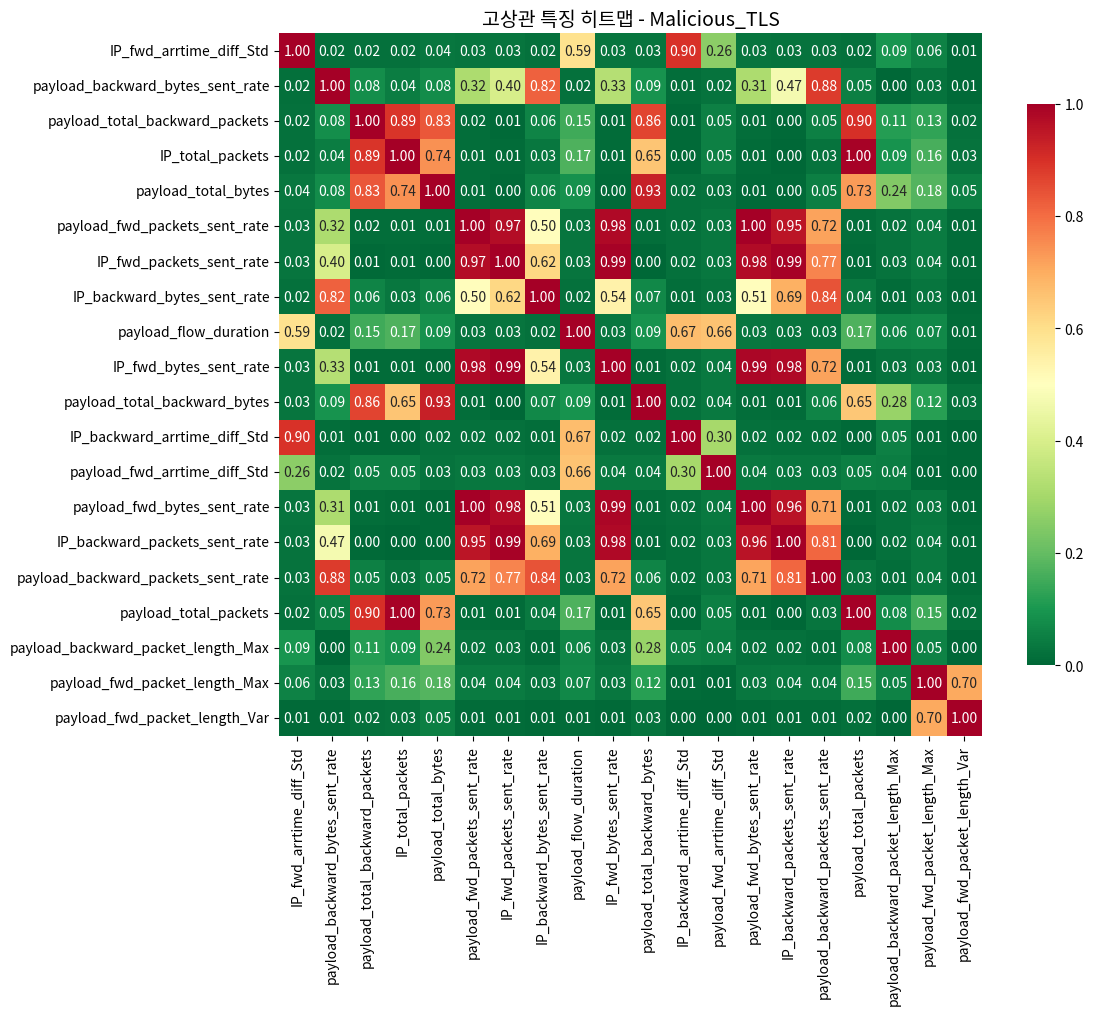

저장: /content/drive/MyDrive/capstone2026/output/features/Malicious_TLS/malicious_tls_corr_heatmap.png


In [6]:
if to_drop_corr:
    drop_list = list(to_drop_corr)[:20]
    sub_corr = corr_matrix.loc[drop_list, drop_list]
    plt.figure(figsize=(12, 10))
    sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='RdYlGn_r',
                vmin=0, vmax=1, square=True, cbar_kws={'shrink': 0.8})
    plt.title('고상관 특징 히트맵 - Malicious_TLS', fontsize=14)
    plt.tight_layout()
    save_path = os.path.join(OUTPUT_DIR, 'malicious_tls_corr_heatmap.png')
    plt.savefig(save_path, dpi=150)
    plt.show()
    print(f'저장: {save_path}')

## 5. Random Forest 특징 중요도

In [7]:
print('[RF 특징 중요도 - 전체 샘플]')

le = LabelEncoder()
y_enc = le.fit_transform(y)

rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X, y_enc)

importances = pd.Series(rf.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=False)

print('\n상위 20개:')
for feat, imp in importances.head(20).items():
    abbr = TLS_COL_MAP.get(feat, feat)
    bar  = '█' * int(imp * 500)
    print(f'  {abbr:<25} {imp:.4f} {bar}')

[RF 특징 중요도 - 전체 샘플]

상위 20개:
  tls_cs_4                  0.0780 ███████████████████████████████████████
  bd_0                      0.0739 ████████████████████████████████████
  tls_cs_3                  0.0380 ██████████████████
  tls_cs_chosen             0.0354 █████████████████
  tls_cs_1                  0.0340 █████████████████
  tls_cs_2                  0.0331 ████████████████
  tls_cs_len                0.0320 ███████████████
  tls_ext_len               0.0315 ███████████████
  bd_1                      0.0308 ███████████████
  tls_cs_0                  0.0279 █████████████
  pay_fwd_pkt_most          0.0211 ██████████
  pay_fwd_pkt_med           0.0209 ██████████
  pay_fwd_pkt_min           0.0190 █████████
  pay_fwd_tot_bytes         0.0185 █████████
  ip_fwd_pkt_max            0.0173 ████████
  bd_2                      0.0169 ████████
  pay_fwd_pkt_mean          0.0164 ████████
  pay_fwd_pkt_var           0.0164 ████████
  ip_fwd_pkt_var            0.0161 ████████
  tls_ve

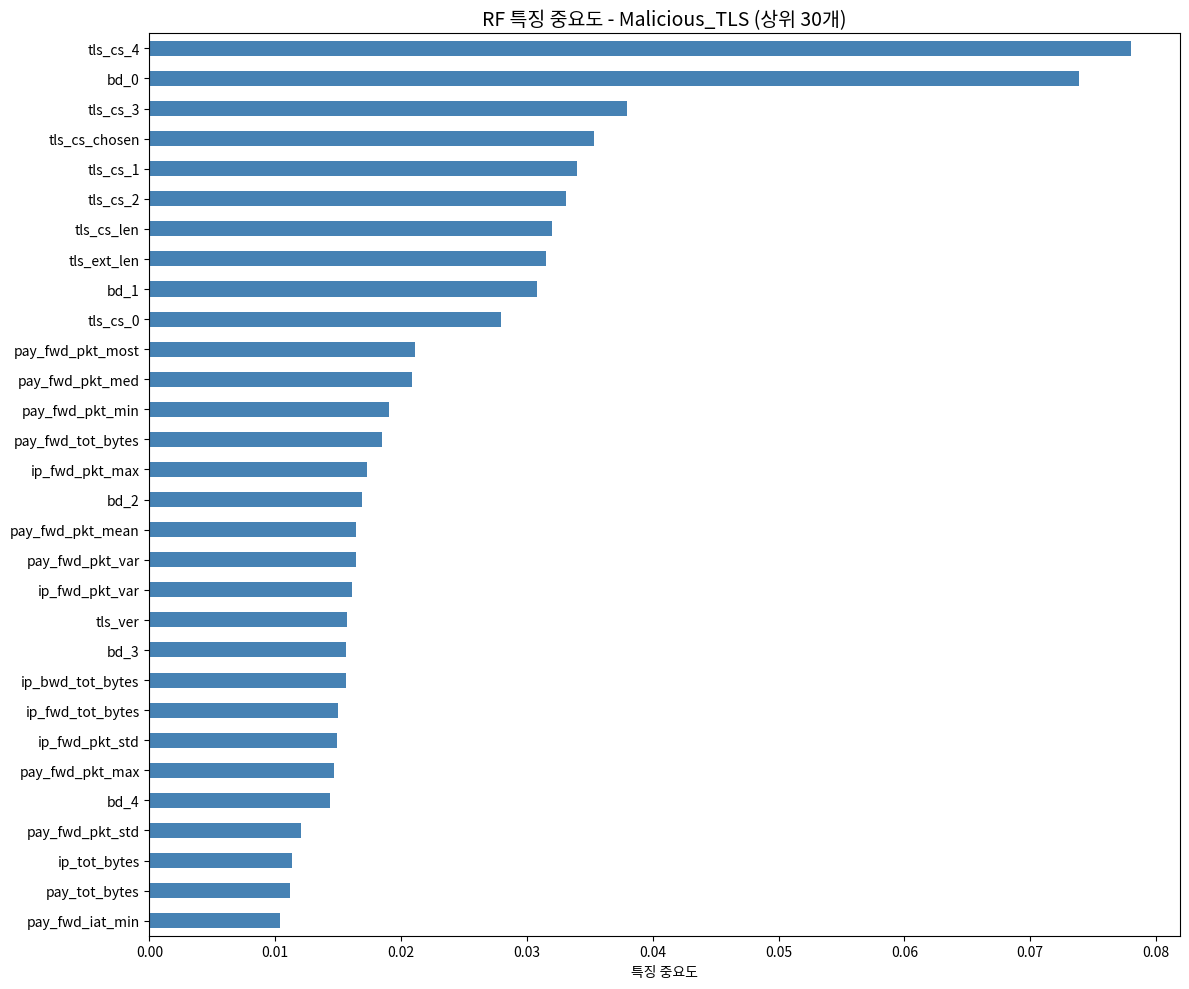

저장: /content/drive/MyDrive/capstone2026/output/features/Malicious_TLS/malicious_tls_feature_importance.png


In [8]:
# 약어명으로 시각화
importances_renamed = importances.copy()
importances_renamed.index = [TLS_COL_MAP.get(f, f) for f in importances.index]

plt.figure(figsize=(12, 10))
importances_renamed.head(30).plot(kind='barh', color='steelblue')
plt.xlabel('특징 중요도')
plt.title('RF 특징 중요도 - Malicious_TLS (상위 30개)', fontsize=14)
plt.gca().invert_yaxis()
plt.tight_layout()
save_path = os.path.join(OUTPUT_DIR, 'malicious_tls_feature_importance.png')
plt.savefig(save_path, dpi=150)
plt.show()
print(f'저장: {save_path}')

## 6. 최적 특징 셋 확정

In [9]:
cumsum = importances.cumsum()
selected_by_importance = importances[cumsum <= 0.99].index.tolist()
final_features = [f for f in selected_by_importance if f not in to_drop_corr]

print('[최적 특징 셋 확정]')
print(f'  전체: {len(feature_cols)}개 → 상관관계 제거: {len(to_drop_corr)}개 → 최종: {len(final_features)}개')
print('\n최종 특징 목록 (약어명):')
for i, f in enumerate(final_features, 1):
    abbr = TLS_COL_MAP.get(f, f)
    imp  = importances.get(f, 0)
    print(f'  {i:2d}. {abbr:<25} ({imp:.4f})')

[최적 특징 셋 확정]
  전체: 117개 → 상관관계 제거: 21개 → 최종: 68개

최종 특징 목록 (약어명):
   1. tls_cs_4                  (0.0780)
   2. bd_0                      (0.0739)
   3. tls_cs_3                  (0.0380)
   4. tls_cs_chosen             (0.0354)
   5. tls_cs_1                  (0.0340)
   6. tls_cs_2                  (0.0331)
   7. tls_cs_len                (0.0320)
   8. tls_ext_len               (0.0315)
   9. bd_1                      (0.0308)
  10. tls_cs_0                  (0.0279)
  11. pay_fwd_pkt_most          (0.0211)
  12. pay_fwd_pkt_med           (0.0209)
  13. pay_fwd_pkt_min           (0.0190)
  14. ip_fwd_pkt_max            (0.0173)
  15. bd_2                      (0.0169)
  16. pay_fwd_pkt_mean          (0.0164)
  17. ip_fwd_pkt_var            (0.0161)
  18. tls_ver                   (0.0157)
  19. bd_3                      (0.0156)
  20. ip_bwd_tot_bytes          (0.0156)
  21. ip_fwd_tot_bytes          (0.0150)
  22. ip_fwd_pkt_std            (0.0149)
  23. bd_4                      

## 7. 컬럼명 약어화 및 저장

In [10]:
df_final = df[final_features + ['Label']].copy()
df_final = df_final.rename(columns=TLS_COL_MAP)

final_cols_renamed = [TLS_COL_MAP.get(f, f) for f in final_features]

print('[컬럼명 약어화 완료]')
print(f'  예시: tls_cipher_suites_4 → {TLS_COL_MAP.get("tls_cipher_suites_4")}')
print(f'  최종 컬럼 수: {len(df_final.columns) - 1}개 (Label 제외)')

out_path  = os.path.join(OUTPUT_DIR, 'malicious_tls_features_final.csv')
feat_path = os.path.join(OUTPUT_DIR, 'malicious_tls_selected_features.txt')

df_final.to_csv(out_path, index=False, encoding='utf-8-sig')
with open(feat_path, 'w') as f:
    for col in final_cols_renamed:
        f.write(col + '\n')

print(f'\n[저장 완료]')
print(f'  데이터  : {out_path}')
print(f'  특징목록: {feat_path}')
print(f'  최종    : {len(df_final):,}행 | {len(final_cols_renamed)}개 특징')
print(f'\n최종 컬럼 목록:')
print(final_cols_renamed)

[컬럼명 약어화 완료]
  예시: tls_cipher_suites_4 → tls_cs_4
  최종 컬럼 수: 68개 (Label 제외)

[저장 완료]
  데이터  : /content/drive/MyDrive/capstone2026/output/features/Malicious_TLS/malicious_tls_features_final.csv
  특징목록: /content/drive/MyDrive/capstone2026/output/features/Malicious_TLS/malicious_tls_selected_features.txt
  최종    : 90,925행 | 68개 특징

최종 컬럼 목록:
['tls_cs_4', 'bd_0', 'tls_cs_3', 'tls_cs_chosen', 'tls_cs_1', 'tls_cs_2', 'tls_cs_len', 'tls_ext_len', 'bd_1', 'tls_cs_0', 'pay_fwd_pkt_most', 'pay_fwd_pkt_med', 'pay_fwd_pkt_min', 'ip_fwd_pkt_max', 'bd_2', 'pay_fwd_pkt_mean', 'ip_fwd_pkt_var', 'tls_ver', 'bd_3', 'ip_bwd_tot_bytes', 'ip_fwd_tot_bytes', 'ip_fwd_pkt_std', 'bd_4', 'pay_fwd_pkt_std', 'ip_tot_bytes', 'pay_fwd_iat_min', 'ip_fwd_pkt_most', 'ip_bwd_tot_pkts', 'ip_bwd_pkt_most', 'ip_fwd_iat_mean', 'ip_bwd_pkt_max', 'ip_fwd_iat_var', 'bd_5', 'ip_fwd_pkt_mean', 'pay_fwd_tot_pkts', 'pay_bwd_pkt_min', 'ip_bwd_iat_max', 'pay_bwd_iat_min', 'ip_bwd_pkt_var', 'pay_bwd_pkt_med', 'ip_fwd_tot_pkts', 'ip_